# Vision — Denoising Gambar (CNN residual / autoencoder vs filter klasik)
**Kapan dipakai:** gambar berbintik/berderau (foto gelap, scan jelek) harus dibersihkan, atau
sebagai praproses sebelum klasifikasi/OCR. Metrik umum: PSNR (dB, makin tinggi makin baik) dan
SSIM (0–1, kemiripan struktur).

**Langkah:** latih jaringan dengan input = gambar bersih + derau Gaussian (`NOISE_SIGMA`),
target = gambar bersih → bandingkan dengan filter klasik (Gaussian blur, median, NL-means).
Model aktif = CNN residual kecil gaya DnCNN: jaringan menebak DERAUNYA, lalu derau dikurangkan
dari input. Alternatif (`#`): autoencoder encoder–decoder.

**Bentuk data:** (1) hanya gambar bersih, derau dibuat sendiri (aktif); (2) pasangan folder
berderau/bersih dengan nama file sama (sel alternatif).

**Data demo:** foto `pets` (train + tanpa_label untuk latih, test untuk evaluasi), dipotong
128×128, ada GIF/grayscale/RGBA.

In [1]:
import glob
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from skimage.metrics import structural_similarity
from torch import nn
from torch.nn import functional

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_FOLDERS = [f"{DATA_FOLDER}/train", f"{DATA_FOLDER}/tanpa_label"]   # gambar bersih
TEST_FOLDER = f"{DATA_FOLDER}/test"
OUTPUT_FOLDER = "../../outputs/vision/autoencoder_denoising"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

IMAGE_SIZE = 128
NOISE_SIGMA = 0.1     # kekuatan derau (0–1), 0.1 ≈ 25 dari 255
EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 0.001
SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data — bentuk 1: hanya gambar bersih (aktif)
Tensor uint8 (jumlah, 3, tinggi, lebar). `convert("RGB")` menyamakan GIF/grayscale/RGBA.

In [3]:
def load_images(paths):
    images = np.zeros((len(paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for i, path in enumerate(paths):
        images[i] = ImageOps.fit(Image.open(path).convert("RGB"), (IMAGE_SIZE, IMAGE_SIZE))
    return torch.tensor(images).permute(0, 3, 1, 2)


train_paths = []
for folder in TRAIN_FOLDERS:
    train_paths.extend(sorted(glob.glob(f"{folder}/*")))
test_paths = sorted(glob.glob(f"{TEST_FOLDER}/*"))
X_train = load_images(train_paths)
X_test = load_images(test_paths)
print("latih:", tuple(X_train.shape), "| test:", tuple(X_test.shape))

latih: (1105, 3, 128, 128) | test: (269, 3, 128, 128)


## (Alternatif) bentuk 2: pasangan folder berderau / bersih
Nama file sama di dua folder. Ganti juga baris `noisy = ...` di sel latih (lihat komentarnya).

In [4]:
# clean_paths = sorted(glob.glob(f"{DATA_FOLDER}/train_bersih/*"))
# noisy_paths = sorted(glob.glob(f"{DATA_FOLDER}/train_berderau/*"))
# X_train = load_images(clean_paths)
# X_train_noisy = load_images(noisy_paths)

## Model: CNN residual kecil (menebak derau)
Tanpa pengecilan ukuran, jadi detail tidak hilang. `denoise` = input − tebakan derau.
Pilih SATU blok `net`: hapus `#` di blok autoencoder dan beri `#` di blok aktif untuk mencoba.

In [5]:
net = nn.Sequential(
    nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
    nn.Conv2d(64, 3, 3, padding=1),
)
# net = nn.Sequential(                                        # autoencoder 128 → 32 → 128
#     nn.Conv2d(3, 64, 3, stride=2, padding=1), nn.ReLU(),
#     nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),
#     nn.ConvTranspose2d(128, 64, 2, stride=2), nn.ReLU(),
#     nn.ConvTranspose2d(64, 3, 2, stride=2),
# )
net = net.to(DEVICE)


def denoise(noisy):
    return (noisy - net(noisy)).clamp(0, 1)

## Latih (input berderau, target bersih)
Derau baru dibuat tiap batch, jadi model tidak pernah melihat derau yang sama dua kali.

In [6]:
optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
for epoch in range(EPOCHS):
    net.train()
    order = torch.randperm(len(X_train))
    total_loss = 0
    for start in range(0, len(order), BATCH_SIZE):
        rows = order[start:start + BATCH_SIZE]
        clean = X_train[rows].float().to(DEVICE) / 255
        noisy = (clean + NOISE_SIGMA * torch.randn_like(clean)).clamp(0, 1)
        # noisy = X_train_noisy[rows].float().to(DEVICE) / 255      # bentuk 2
        loss = functional.mse_loss(denoise(noisy), clean)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(rows)
    if (epoch + 1) % 5 == 0:
        print("epoch", epoch + 1, "loss", round(total_loss / len(X_train), 5))

epoch 5 loss 0.00232


epoch 10 loss 0.00175


epoch 15 loss 0.00162


epoch 20 loss 0.00158


## Test berderau (derau dibuat sekali dengan seed tetap) + hasil model

In [7]:
generator = torch.Generator().manual_seed(SEED)
clean_test = X_test.float() / 255
noise = torch.randn(clean_test.shape, generator=generator)
noisy_test = (clean_test + NOISE_SIGMA * noise).clamp(0, 1)

net.eval()
model_batches = []
with torch.no_grad():
    for start in range(0, len(noisy_test), BATCH_SIZE):
        model_batches.append(denoise(noisy_test[start:start + BATCH_SIZE].to(DEVICE)).cpu())
model_test = torch.cat(model_batches)

## Pembanding: filter klasik OpenCV (tanpa latih)
NL-means: `h` = kekuatan penghalusan (0–255), lalu ukuran jendela 5 dan area cari 11. Di gambar
kecil (128 px) hasilnya mirip Gaussian blur; di gambar besar berpola biasanya lebih unggul.

In [8]:
def to_tensor(arrays):
    images = torch.tensor(np.stack(arrays)).permute(0, 3, 1, 2)
    return images.float() / 255


gaussian = []
median = []
nlmeans = []
for image in noisy_test:
    array = np.ascontiguousarray((image.permute(1, 2, 0).numpy() * 255).astype(np.uint8))
    gaussian.append(cv2.GaussianBlur(array, (5, 5), 0))
    median.append(cv2.medianBlur(array, 3))
    nlmeans.append(cv2.fastNlMeansDenoisingColored(array, None, 20, 20, 5, 11))
outputs = {"berderau": noisy_test, "gaussian": to_tensor(gaussian), "median": to_tensor(median),
           "nlmeans": to_tensor(nlmeans), "model": model_test}

## Evaluasi: PSNR dan SSIM rata-rata di test
PSNR = −10 × log10(MSE), naik 3 dB ≈ error turun setengah. SSIM 1 = struktur sama persis.

In [9]:
def psnr_ssim(images):
    mse = ((images - clean_test) ** 2).mean(dim=(1, 2, 3))
    psnr = (-10 * torch.log10(mse)).numpy()
    ssim = []
    for result, clean in zip(images, clean_test):
        ssim.append(structural_similarity(result.permute(1, 2, 0).numpy(),
                                          clean.permute(1, 2, 0).numpy(),
                                          channel_axis=2, data_range=1.0))
    return psnr, np.array(ssim)


scores = pd.DataFrame(index=list(outputs), columns=["PSNR", "SSIM"], dtype=float)
per_image = {}
for name in outputs:
    psnr, ssim = psnr_ssim(outputs[name])
    per_image[name] = psnr
    scores.loc[name] = [psnr.mean(), ssim.mean()]
scores.round(3)

,PSNR,SSIM
berderau,20.383,0.460
gaussian,26.400,0.750
median,25.438,0.668
nlmeans,26.347,0.731
model,28.137,0.814


## Contoh: bersih / berderau / NL-means / model (potongan tengah diperbesar)

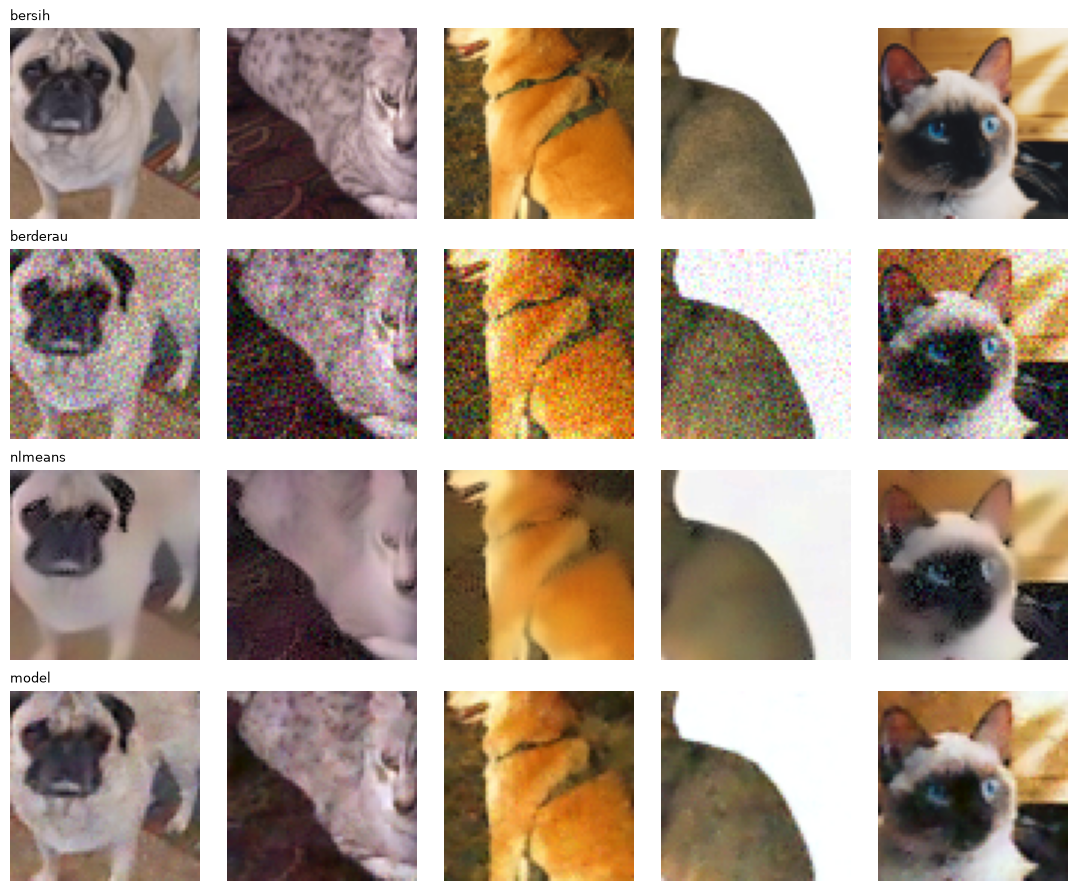

In [10]:
rows_to_show = ["bersih", "berderau", "nlmeans", "model"]
images_to_show = {"bersih": clean_test, "berderau": noisy_test,
                  "nlmeans": outputs["nlmeans"], "model": model_test}
fig, axes = plt.subplots(4, 5, figsize=(11, 9))
for grid_row, name in enumerate(rows_to_show):
    for column in range(5):
        crop = images_to_show[name][column, :, 32:96, 32:96]
        axes[grid_row, column].imshow(crop.permute(1, 2, 0))
        axes[grid_row, column].axis("off")
    axes[grid_row, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUTPUT_FOLDER}/contoh_denoising.png", dpi=90)
plt.show()

## Hasil per gambar + simpan gambar hasil model

In [11]:
result = pd.DataFrame()
result["id"] = pd.Series(test_paths).apply(os.path.basename)
result["psnr_berderau"] = per_image["berderau"]
result["psnr_model"] = per_image["model"]
result.to_csv(f"{OUTPUT_FOLDER}/hasil.csv", index=False)
os.makedirs(f"{OUTPUT_FOLDER}/bersih", exist_ok=True)
for image_id, image in zip(result["id"], model_test):
    array = (image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    Image.fromarray(array).save(f"{OUTPUT_FOLDER}/bersih/{os.path.splitext(image_id)[0]}.png")
result.head()

,id,psnr_berderau,psnr_model
0,test_0001.jpg,20.048151,28.379290
1,test_0002.jpg,20.700867,28.166733
2,test_0003.jpg,20.348740,27.244663
3,test_0004.jpg,21.621403,31.791632
4,test_0005.jpg,20.484354,27.720413


## Masalah umum
- **Hasil buram:** model terlalu dangkal atau `NOISE_SIGMA` latih lebih besar dari derau asli.
  Samakan `NOISE_SIGMA` dengan derau di soal (perkirakan dari bagian gambar yang polos).
- **Derau di soal bukan Gaussian** (bintik garam-merica, JPEG, garis): buat derau latih yang
  mirip, atau pakai bentuk 2 bila ada pasangan. Untuk garam-merica, `median` sering cukup.
- **Gambar test ukurannya beda dengan latih:** model ini tanpa pengecilan, jadi bisa langsung
  dijalankan di ukuran apa pun (satu gambar per batch).